<a href="https://colab.research.google.com/github/wonhoyeo-oss/CV2026/blob/main/homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [178]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from sklearn.datasets import make_blobs
from sklearn.datasets import make_moons
from matplotlib import pyplot
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt

In [179]:
def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0).reshape(xx.shape)
    acc = np.mean((model.predict(X, verbose=0) > 0.5).astype(int).flatten() == y)

    plt.figure(figsize=(6, 5))
    plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.5)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')
    plt.title(f"{title}\nAccuracy: {acc:.2f}")
    plt.xlabel("x1"); plt.ylabel("x2")
    plt.show()

In [180]:
def add_boundary(ax, model):
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.5)

In [181]:
# random seed for always same results
tf.random.set_seed(678)
print(tf.__version__)

2.21.0


### model

In [182]:
model = Sequential()
# first dense layer
model.add(Dense(units=2, input_shape=(2,), activation='sigmoid'))
#model.add(Dense(units=4, activation='sigmoid'))
#model.add(Dense(units=4, activation='sigmoid'))
#model.add(Dense(units=2, activation='sigmoid'))
model.add(Dense(units=1, activation='sigmoid'))
# loss function and optimization

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [183]:
model.compile(tf.keras.optimizers.SGD(learning_rate=0.2), loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 2)              │             6 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (36.00 B)

 Trainable params: 9 (36.00 B)

 Non-trainable params: 0 (0.00 B)

### Simple Data Xy

In [184]:
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
y = np.array([0.,1.,1.,1.])

In [185]:
# generate 2d classification dataset
X, y = make_moons(n_samples=50, noise=.06)

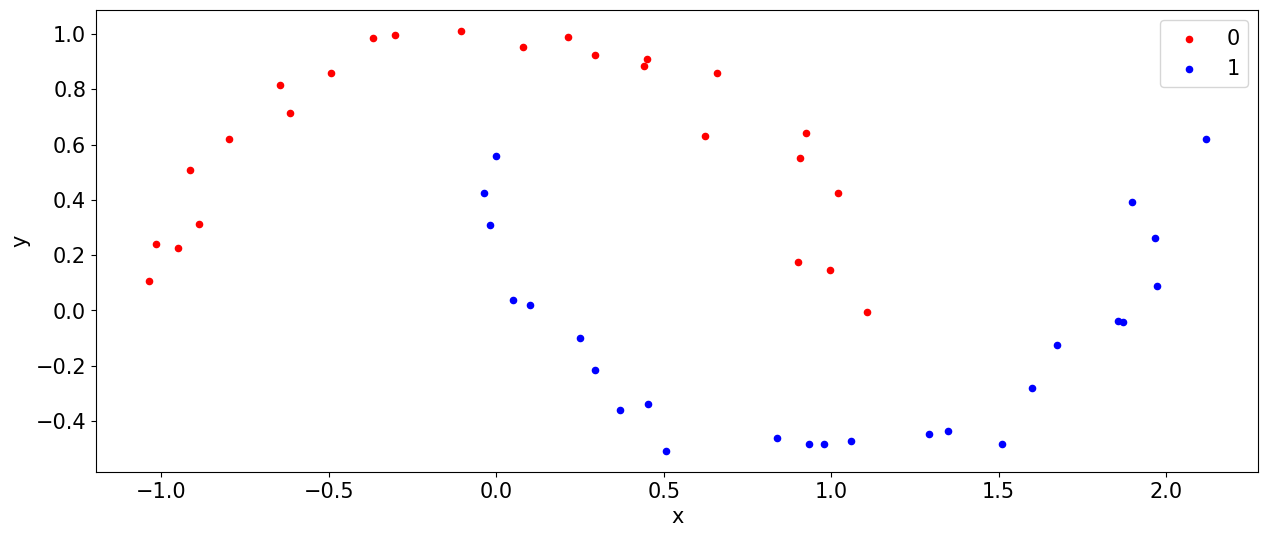

In [186]:
# scatter plot, dots colored by class value
df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
colors = {0:'red', 1:'blue', 2:'green'}
fig, ax = pyplot.subplots()
grouped = df.groupby('label')
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
add_boundary(ax, model)
pyplot.show()

### model.fit

In [187]:
class callback(tf.keras.callbacks.Callback):
    SHOW_NUMBER = 1000
    counter = 0
    epoch = 0

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch = epoch

    def on_train_batch_end(self, batch, logs=None):
        if self.counter == self.SHOW_NUMBER or self.epoch == 1:
            print('Epoch: ' + str(self.epoch) + ' loss: ' + str(logs['loss']))
            if self.epoch > 1:
                self.counter = 0
        self.counter += 1

In [188]:
batchNum = 100
epochNum = 5000

In [189]:
history = model.fit(X, y, batch_size=batchNum, epochs=epochNum, callbacks=[callback()], verbose=0)

Epoch: 1 loss: 0.7445272207260132
Epoch: 1000 loss: 0.31808218359947205
Epoch: 2000 loss: 0.31237271428108215
Epoch: 3000 loss: 0.30972152948379517
Epoch: 4000 loss: 0.30806389451026917


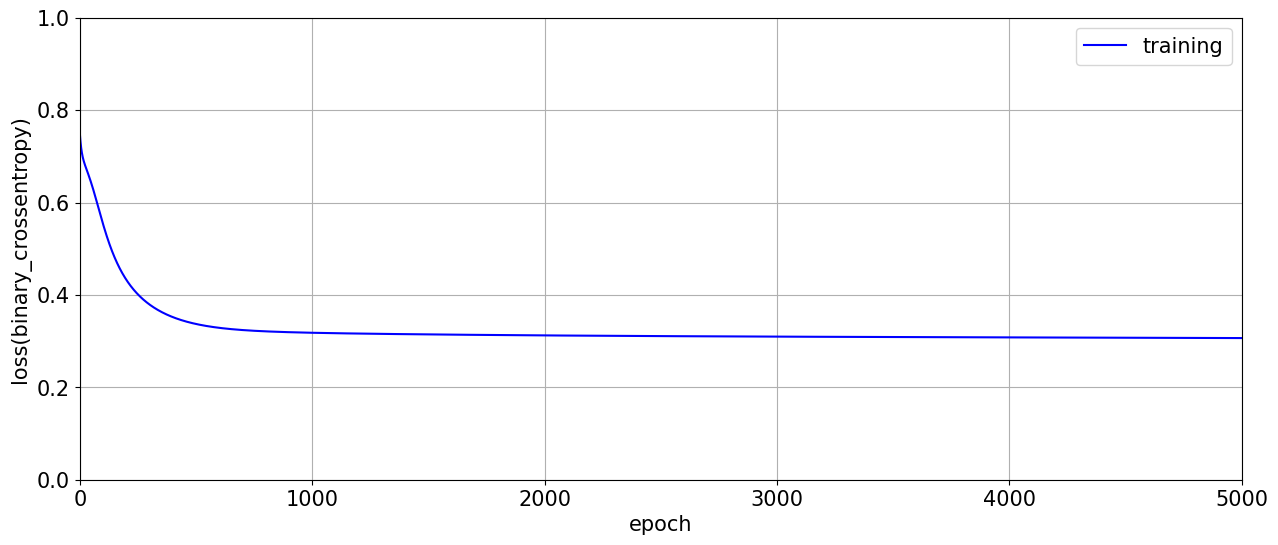

In [190]:
plt.plot(pd.DataFrame(history.history)[['loss']],'b', label='training')
# plt.figure(figsize=(5,5), dpi=10000, facecolor='w', edgecolor='k')
plt.xlabel("epoch")
plt.ylabel("loss(binary_crossentropy)")  # "Loss(MAE)"  logcosh
plt.rcParams['figure.figsize'] = [15, 6]
font = {'weight' : 'normal', 'size' : 15}
plt.rc('font', **font)
# plt.title('node #:' + str(nodeNum)+' / layer #:'+str(layerNum))
plt.grid(True)
plt.legend()
plt.xlim(-1, epochNum+1)
plt.ylim(0, 1)
# plt.savefig(MODEL_SAVE_FOLDER_PATH+'_learningcurve_'+case_name+'.png', dpi=300)
plt.show()

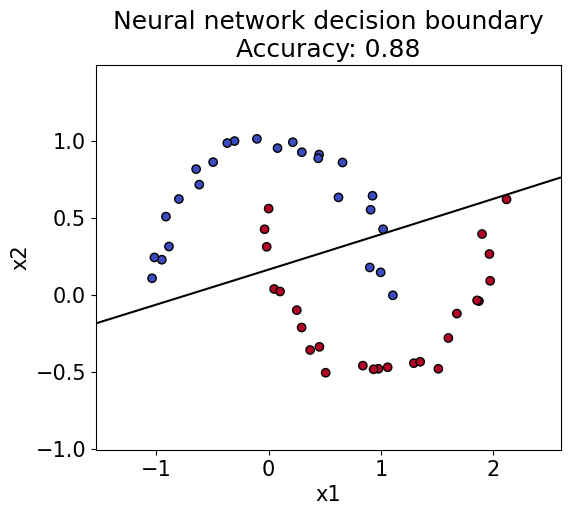

In [191]:
# 결정 경계 그래프: 기존 model, X, y를 그대로 사용
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
Z = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0).reshape(xx.shape)

acc = np.mean((model.predict(X, verbose=0) > 0.5).astype(int).flatten() == y)

plt.figure(figsize=(6, 5))
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.5)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k')
plt.title(f"Neural network decision boundary\nAccuracy: {acc:.2f}")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

In [192]:
print("first layer weights: ",model.layers[0].get_weights()[0])
print("first layer bias: ",model.layers[0].get_weights()[1])
print("second layer weights: ",model.layers[1].get_weights()[0])
print("second layer bias: ",model.layers[1].get_weights()[1])

first layer weights:  [[-0.35  0.57]
 [ 2.27 -2.09]]
first layer bias:  [0.5  0.89]
second layer weights:  [[-3.86]
 [ 6.64]]
second layer bias:  [-1.49]


In [193]:
py = model.predict(X)
lpy = tf.cast(py > 0.5, dtype=tf.float32)
for i in range(0, len(py), 1):
  print(y[i], py[i], lpy.numpy()[i])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1 [0.72] [1.]
1 [0.53] [1.]
0 [0.02] [0.]
1 [0.94] [1.]
1 [0.97] [1.]
1 [0.32] [0.]
0 [0.05] [0.]
1 [0.93] [1.]
0 [0.47] [0.]
0 [0.03] [0.]
1 [0.97] [1.]
1 [0.94] [1.]
1 [0.13] [0.]
1 [0.97] [1.]
0 [0.72] [1.]
0 [0.02] [0.]
0 [0.04] [0.]
1 [0.89] [1.]
0 [0.17] [0.]
1 [0.97] [1.]
0 [0.03] [0.]
1 [0.83] [1.]
1 [0.67] [1.]
1 [0.97] [1.]
0 [0.07] [0.]
0 [0.04] [0.]
0 [0.03] [0.]
0 [0.28] [0.]
0 [0.05] [0.]
1 [0.97] [1.]
0 [0.06] [0.]
1 [0.91] [1.]
0 [0.02] [0.]
1 [0.83] [1.]
0 [0.19] [0.]
0 [0.17] [0.]
0 [0.03] [0.]
0 [0.76] [1.]
1 [0.96] [1.]
0 [0.07] [0.]
0 [0.14] [0.]
0 [0.87] [1.]
0 [0.22] [0.]
1 [0.21] [0.]
0 [0.29] [0.]
1 [0.94] [1.]
1 [0.7] [1.]
1 [0.94] [1.]
1 [0.97] [1.]
1 [0.98] [1.]


In [194]:
model.weights

[<Variable path=sequential_8/dense_16/kernel, shape=(2, 2), dtype=float32, value=[[-0.35  0.57]
  [ 2.27 -2.09]]>,
 <Variable path=sequential_8/dense_16/bias, shape=(2,), dtype=float32, value=[0.5  0.89]>,
 <Variable path=sequential_8/dense_17/kernel, shape=(2, 1), dtype=float32, value=[[-3.86]
  [ 6.64]]>,
 <Variable path=sequential_8/dense_17/bias, shape=(1,), dtype=float32, value=[-1.49]>]

In [195]:
lpy = np.array(lpy)
print(lpy)

[[1.]
 [1.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [1.]
 [1.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [1.]
 [0.]
 [1.]
 [0.]
 [1.]
 [1.]
 [1.]
 [0.]
 [0.]
 [0.]
 [0.]
 [0.]
 [1.]
 [0.]
 [1.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]


In [196]:
lpy = np.reshape(lpy, (len(y),))
print(y.shape, lpy.shape)

(50,) (50,)


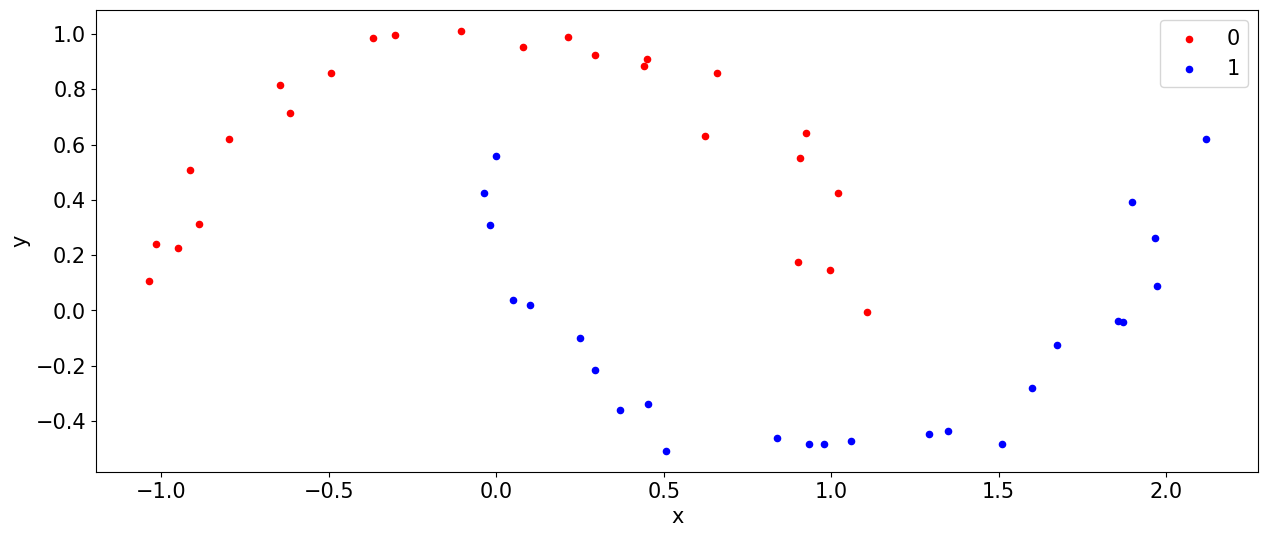

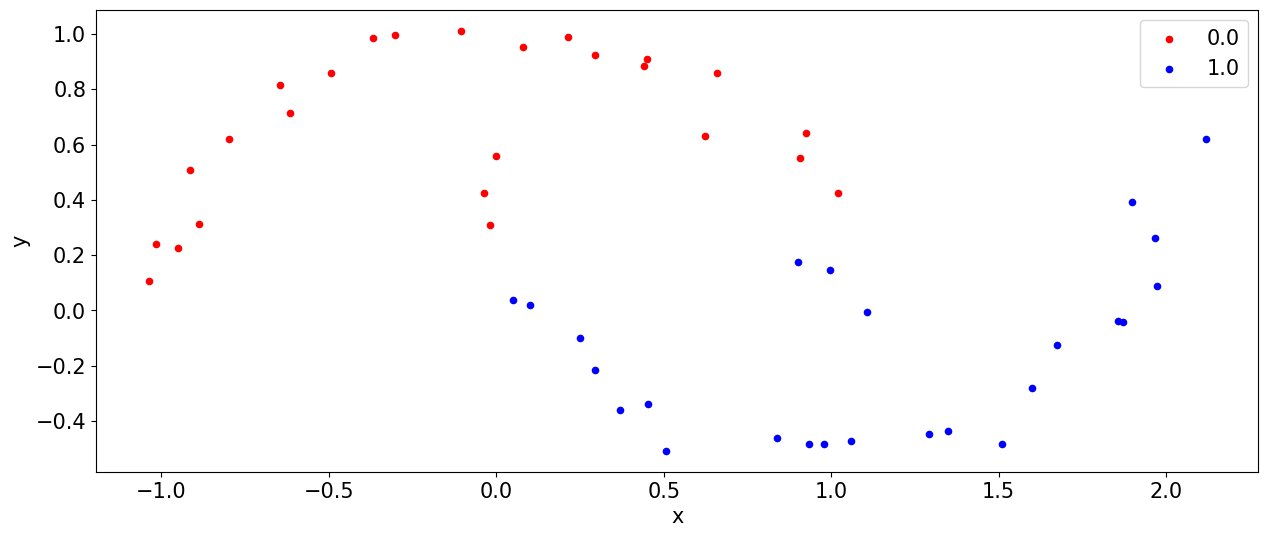

In [197]:
colors = {0:'red', 1:'blue'}

df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
grouped = df.groupby('label')
fig, ax = pyplot.subplots()
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

df = DataFrame(dict(x=X[:,0], y=X[:,1], label=lpy))
grouped = df.groupby('label')
fig, ax = pyplot.subplots()
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

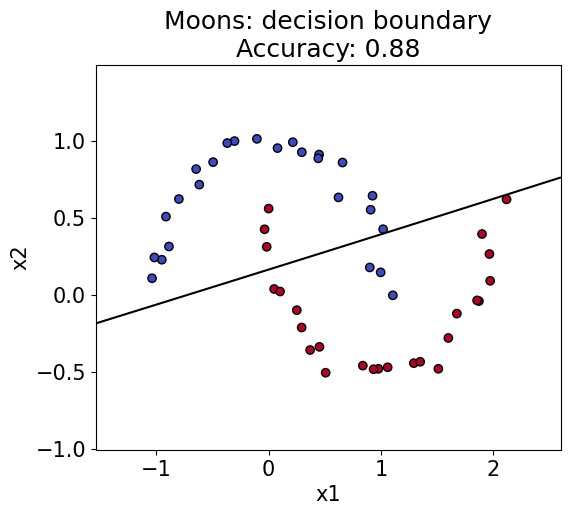

In [198]:
plot_boundary(model, X, y, "Moons: decision boundary")

# generate blobs of points with a Gaussian distribution.

In [199]:
# generate 2d classification dataset
X, y = make_blobs(n_samples=100, centers=2, n_features=2)

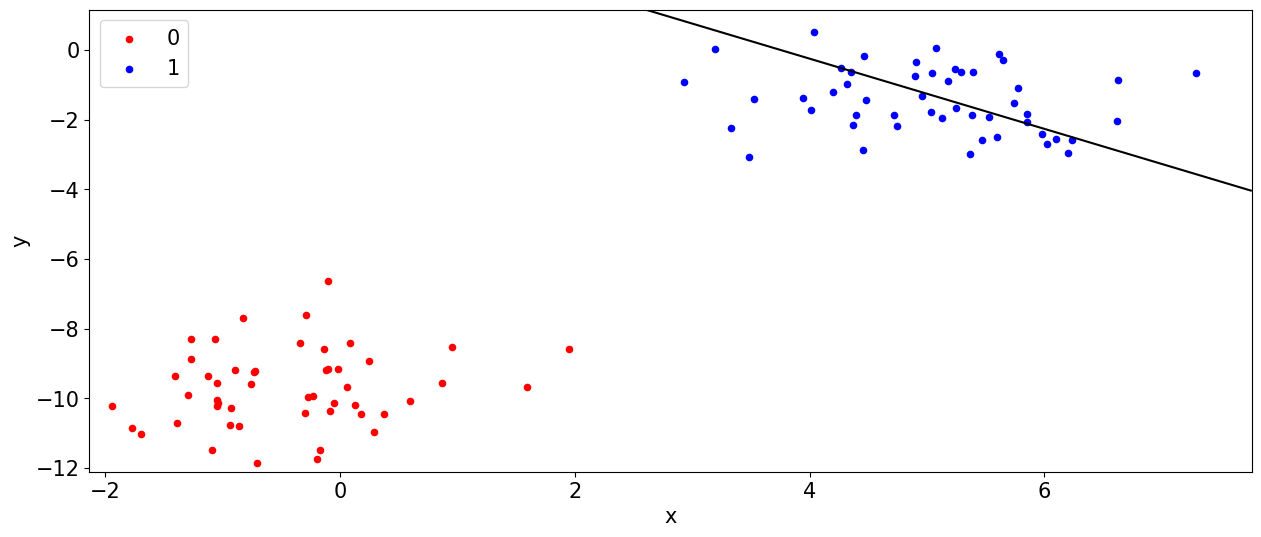

In [200]:
# scatter plot, dots colored by class value
df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
colors = {0:'red', 1:'blue', 2:'green'}
fig, ax = pyplot.subplots()
grouped = df.groupby('label')
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
    add_boundary(ax, model_blobs)
pyplot.show()

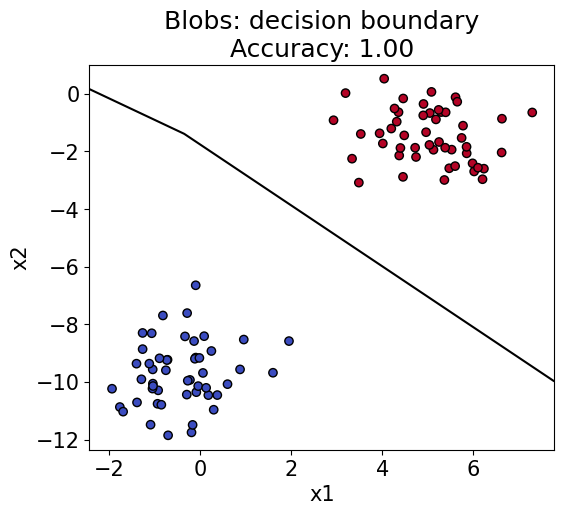

In [201]:
from tensorflow.keras.layers import Input

model_blobs = Sequential([
    Input(shape=(2,)),
    Dense(2, activation='relu'),
    Dense(1, activation='sigmoid')
])
model_blobs.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_blobs.fit(X, y, epochs=300, batch_size=10, verbose=0)

plot_boundary(model_blobs, X, y, "Blobs: decision boundary")

In [202]:
np.set_printoptions(linewidth=220, precision=2)
print(X.T)

[[  0.29   4.36   4.01  -0.14   4.2    7.29   0.95   5.04   5.29   4.96  -0.93   6.63   5.08  -1.04   5.12  -1.27  -1.4    5.25   5.39   5.61  -0.19  -0.17   0.37   5.98  -1.05   5.52   0.06   4.46   4.27  -0.1    5.18
    4.37  -0.72   6.02   1.95  -1.39   0.87   0.18   4.32  -0.82   3.19  -0.74   5.85  -1.27   4.9    2.93  -0.23   4.9   -1.77   3.53  -1.05  -0.12   3.33  -0.94   0.24  -0.9   -0.1   -0.3    5.85  -0.71  -1.07   0.6
   -0.29  -0.28   6.23   3.48  -1.09   4.45   4.72  -0.09   4.4   -0.34   5.47   5.36  -1.7    5.03  -0.86   6.1    5.74   4.74  -1.04   6.62   6.2   -1.12  -0.05   4.04  -0.76   1.6    0.08   3.94   5.6    0.13  -0.02
    4.48  -1.94  -1.3    5.77   5.65   5.24   5.38]
 [-10.96  -0.64  -1.72  -8.58  -1.2   -0.65  -8.53  -0.67  -0.63  -1.33 -10.29  -0.86   0.07 -10.06  -1.94  -8.3   -9.36  -1.67  -0.64  -0.12 -11.75 -11.49 -10.45  -2.41  -9.56  -1.94  -9.69  -0.16  -0.51  -9.15  -0.89
   -2.14  -9.23  -2.69  -8.58 -10.71  -9.56 -10.46  -0.97  -7.69   0.03  

In [203]:
print(y)

[0 1 1 0 1 1 0 1 1 1 0 1 1 0 1 0 0 1 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 1 1 0 1 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 1 1 0 1 0 1 1 1 0 1 1 0 0 1 0 0 0 1 1 0 0 1 0 0 1 1 1 1]


In [204]:
# generate 2d classification dataset
X, y = make_moons(n_samples=100, noise=.16)

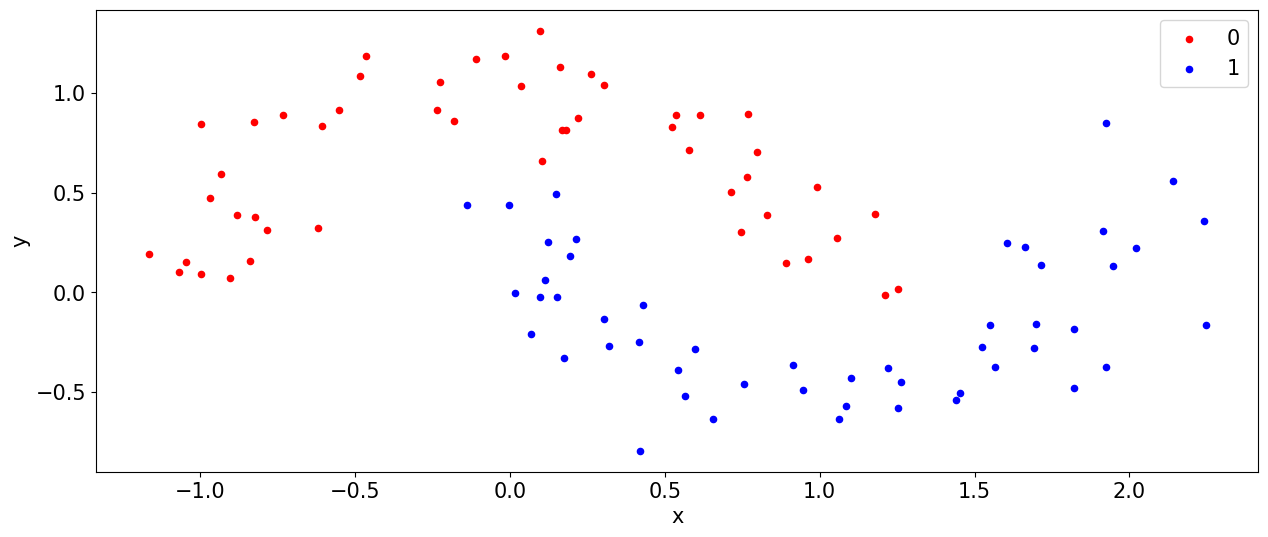

In [205]:
# scatter plot, dots colored by class value
df = DataFrame(dict(x=X[:,0], y=X[:,1], label=y))
colors = {0:'red', 1:'blue', 2:'green'}
fig, ax = pyplot.subplots()
grouped = df.groupby('label')
for key, group in grouped:
    group.plot(ax=ax, kind='scatter', x='x', y='y', label=key, color=colors[key])
pyplot.show()

In [206]:
np.set_printoptions(linewidth=220, precision=2)
print(X.T)

[[-2.25e-01  1.91e+00  1.74e-01  5.37e-01  2.24e+00 -8.26e-01  5.23e-01  4.19e-01  1.68e-01  1.92e+00 -7.84e-01  3.02e-01 -1.05e+00 -8.22e-01  1.51e-02  2.02e+00  1.06e+00  9.14e-01  1.06e+00 -9.02e-01 -1.07e+00
   1.95e+00  1.48e-01  6.14e-01  2.21e-01  5.79e-01  1.82e-01  1.21e+00  8.29e-01  1.18e+00 -1.82e-01  1.70e+00  7.98e-01 -9.97e-01 -2.34e-01  1.93e-01  1.92e+00  1.52e+00  1.71e+00  1.50e-01  4.16e-01  1.26e+00
   1.60e+00  3.05e-01  7.47e-01 -1.39e-01  2.13e-01  4.28e-01  1.09e+00 -4.83e-01 -1.47e-02  9.63e-01 -4.37e-03  9.91e-01  1.69e+00  1.66e+00  1.45e+00  9.56e-02 -7.34e-01  7.14e-01  2.25e+00  1.57e+00  9.60e-02
   1.25e+00  1.61e-01 -6.06e-01 -9.32e-01  5.44e-01  8.92e-01  1.10e+00  7.65e-01 -9.96e-01  1.04e-01 -9.68e-01  3.48e-02  1.55e+00  6.56e-01  2.63e-01  1.82e+00  5.96e-01  6.91e-02 -4.63e-01  1.44e+00  7.67e-01
  -5.51e-01  2.14e+00  3.21e-01 -6.20e-01  7.54e-01  9.48e-01 -1.17e+00  1.21e-01 -8.38e-01  1.82e+00 -1.09e-01  1.14e-01  1.22e+00  5.65e-01  1.25e+00 

In [207]:
print(y)

[0 1 1 0 1 0 0 1 0 1 0 1 0 0 1 1 1 1 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 0 0 0 1 0 1 1 1 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 1 0 1 1 1 0 1 0 0 1 1 0 1 1 0 1 0 1 0 1 1 1 1 0]


# ML ex2data1

In [208]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [209]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##### ex2data1, data2
https://drive.google.com/file/d/176uBDnnuoyLQuqR2oeWC3BkBL023puwQ/view?usp=sharing

https://drive.google.com/file/d/1EJf9oTrbjW-jE6oJyrfA1ukuQU0nyxbw/view?usp=sharing

In [210]:
import gdown
import pandas as pd

gdown.download(id='176uBDnnuoyLQuqR2oeWC3BkBL023puwQ', output='ex2data1.txt', quiet=False)

data = pd.read_csv('ex2data1.txt', sep=',',
                   names=['Exam 1 Score', 'Exam 2 Score', 'Result'], header=None)
data


Downloading...
From: https://drive.google.com/uc?id=176uBDnnuoyLQuqR2oeWC3BkBL023puwQ
To: /content/ex2data1.txt
100%|██████████| 3.77k/3.77k [00:00<00:00, 4.32MB/s]


,Exam 1 Score,Exam 2 Score,Result
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1
...,...,...,...
95,83.489163,48.380286,1
96,42.261701,87.103851,1
97,99.315009,68.775409,1
98,55.340018,64.931938,1


In [211]:
data

,Exam 1 Score,Exam 2 Score,Result
0,34.623660,78.024693,0
1,30.286711,43.894998,0
2,35.847409,72.902198,0
3,60.182599,86.308552,1
4,79.032736,75.344376,1
...,...,...,...
95,83.489163,48.380286,1
96,42.261701,87.103851,1
97,99.315009,68.775409,1
98,55.340018,64.931938,1


In [212]:
import seaborn as sns

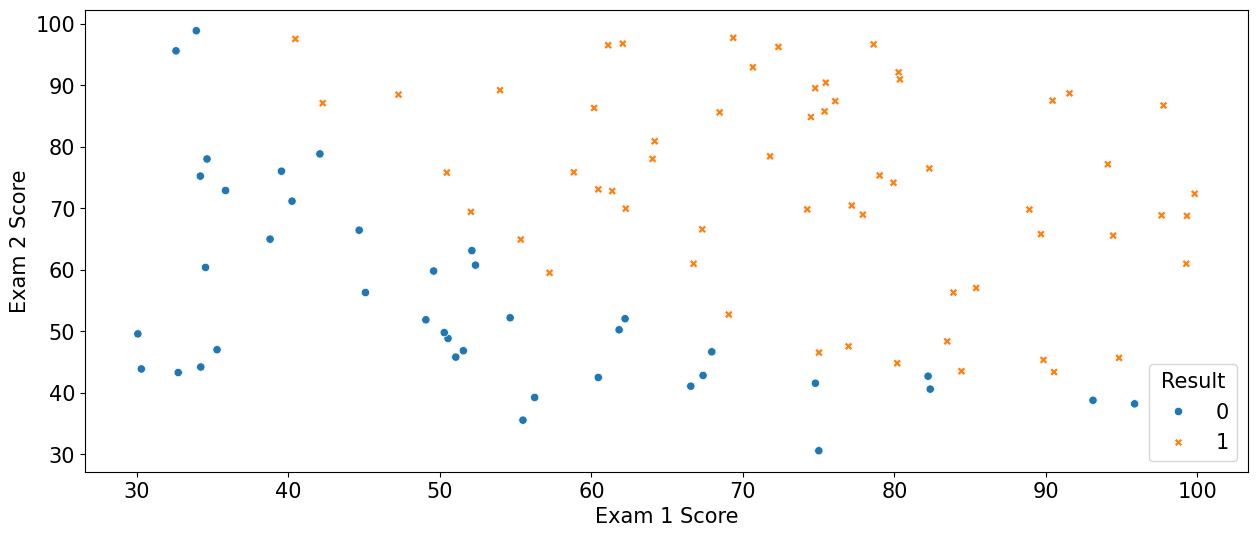

In [213]:
g =sns.scatterplot(x = 'Exam 1 Score', y = 'Exam 2 Score', hue = 'Result', data = data, style = 'Result')

In [214]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input

# moons 데이터 (노이즈를 줘서 두 클래스가 조금 겹치게)
Xm, ym = make_moons(n_samples=200, noise=0.25, random_state=42)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.3, random_state=42)

def show_moons(model, title):
    x_min, x_max = Xm[:, 0].min() - 0.5, Xm[:, 0].max() + 0.5
    y_min, y_max = Xm[:, 1].min() - 0.5, Xm[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0).reshape(xx.shape)

    tr = np.mean((model.predict(Xtr, verbose=0) > 0.5).astype(int).flatten() == ytr)
    te = np.mean((model.predict(Xte, verbose=0) > 0.5).astype(int).flatten() == yte)

    plt.figure(figsize=(6, 5))
    plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=1.5)
    plt.scatter(Xte[:, 0], Xte[:, 1], c=yte, cmap=plt.cm.coolwarm, edgecolors='k')
    plt.title(f"{title}\nTrain acc: {tr:.2f} / Test acc: {te:.2f}")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

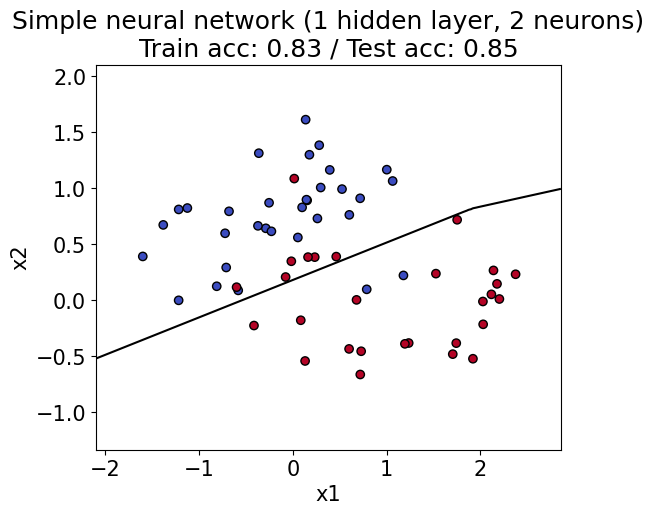

In [216]:
tf.random.set_seed(42)
m_simple = Sequential([
    Input(shape=(2,)),
    Dense(2, activation='relu'),
    Dense(1, activation='sigmoid')
])
m_simple.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
m_simple.fit(Xtr, ytr, epochs=300, batch_size=10, verbose=0)

show_moons(m_simple, "Simple neural network (1 hidden layer, 2 neurons)")

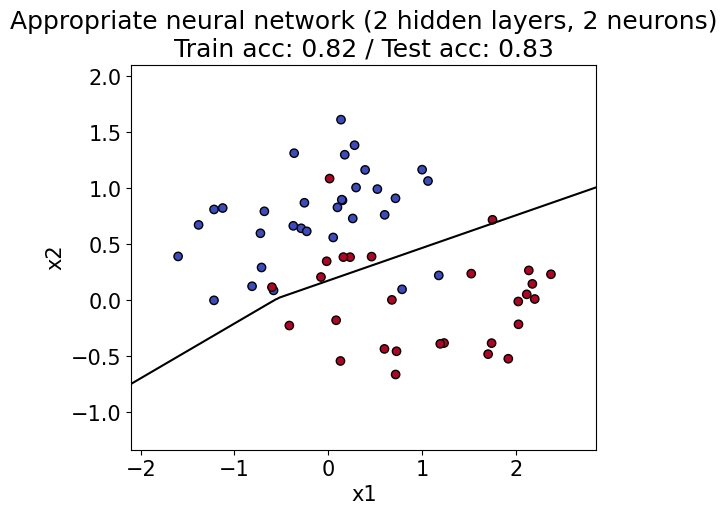

In [217]:
tf.random.set_seed(42)
m_mid = Sequential([
    Input(shape=(2,)),
    Dense(2, activation='relu'),
    Dense(2, activation='relu'),
    Dense(1, activation='sigmoid')
])
m_mid.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
m_mid.fit(Xtr, ytr, epochs=300, batch_size=10, verbose=0)

show_moons(m_mid, "Appropriate neural network (2 hidden layers, 2 neurons)")

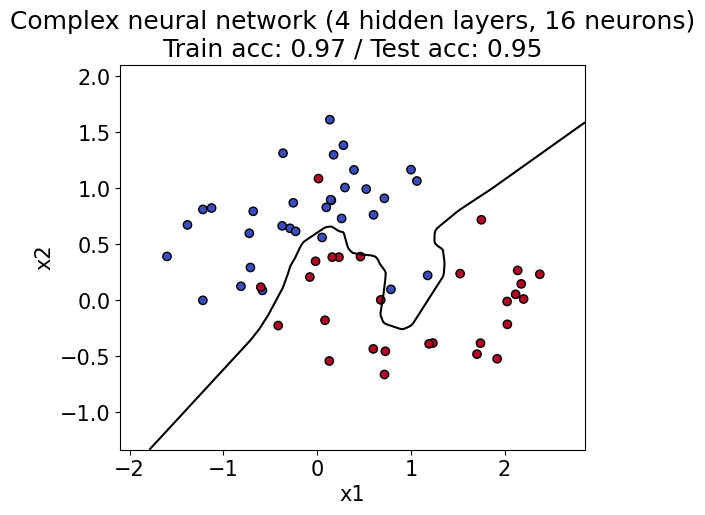

In [218]:
tf.random.set_seed(42)
m_complex = Sequential([
    Input(shape=(2,)),
    Dense(16, activation='relu'),
    Dense(16, activation='relu'),
    Dense(16, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
m_complex.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
m_complex.fit(Xtr, ytr, epochs=300, batch_size=10, verbose=0)

show_moons(m_complex, "Complex neural network (4 hidden layers, 16 neurons)")